<a href="https://colab.research.google.com/github/ojaswi-raya/One-Look/blob/main/02_labels_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q rasterio
D = "/content/drive/MyDrive/one-look/data/HandLabeled"
OUT = "/content/drive/MyDrive/one-look/data"

Mounted at /content/drive


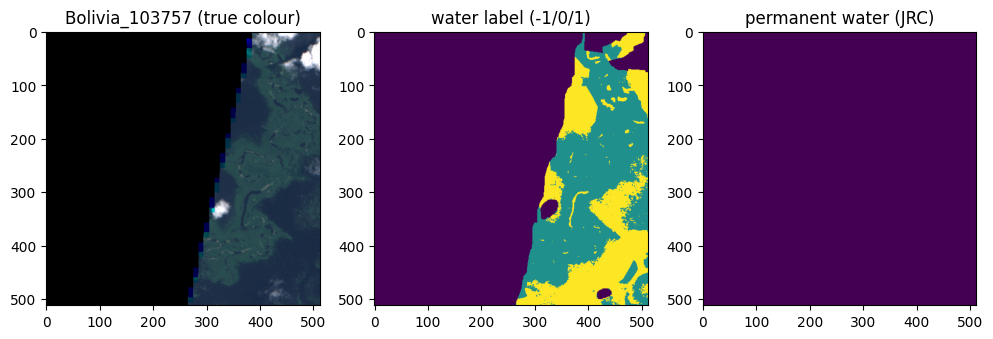

In [3]:
import rasterio, numpy as np, matplotlib.pyplot as plt, os
cid = sorted(os.listdir(f"{D}/LabelHand"))[0].replace("_LabelHand.tif", "")
s2  = rasterio.open(f"{D}/S2Hand/{cid}_S2Hand.tif").read()
lab = rasterio.open(f"{D}/LabelHand/{cid}_LabelHand.tif").read(1)
jrc = rasterio.open(f"{D}/JRCWaterHand/{cid}_JRCWaterHand.tif").read(1)
rgb = np.clip(s2[[3, 2, 1]].transpose(1, 2, 0) / 3000, 0, 1)   # bands B4, B3, B2 = red, green, blue
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(rgb); ax[0].set_title(f"{cid} (true colour)")
ax[1].imshow(lab, vmin=-1, vmax=1); ax[1].set_title("water label (-1/0/1)")
ax[2].imshow(jrc); ax[2].set_title("permanent water (JRC)")
plt.show()

In [4]:
import pandas as pd
THRESHOLD = 0.01   # ALERT if more than 1% of the chip is flood water

rows = []
for f in sorted(os.listdir(f"{D}/LabelHand")):
    cid = f.replace("_LabelHand.tif", "")
    lab = rasterio.open(f"{D}/LabelHand/{cid}_LabelHand.tif").read(1)
    jrc = rasterio.open(f"{D}/JRCWaterHand/{cid}_JRCWaterHand.tif").read(1)
    valid = lab != -1                        # ignore "no data" pixels
    flood = (lab == 1) & (jrc != 1)          # water that is NOT permanent water
    frac = flood[valid].mean() if valid.any() else 0.0
    rows.append({"chip_id": cid, "country": cid.split("_")[0],
                 "flood_fraction": frac, "label": int(frac > THRESHOLD)})
df = pd.DataFrame(rows)
print(df.label.value_counts())
df.groupby("country").label.agg(["count", "sum"]).rename(columns={"sum": "n_alert"})

label
1    273
0    173
Name: count, dtype: int64


,count,n_alert
country,,
Bolivia,15,11
Ghana,53,19
India,68,58
Mekong,30,24
Nigeria,18,12
Pakistan,28,14
Paraguay,67,38
Somalia,26,15
Spain,30,21


In [6]:
SPLIT = {
    "test":  ["Bolivia", "Ghana"],      # Bolivia always held out, as in the dataset paper
    "val":   ["Spain", "Sri-Lanka"],
}
SPLIT["train"] = sorted(set(df.country) - set(SPLIT["test"]) - set(SPLIT["val"]))
df["split"] = df.country.map({c: s for s, cs in SPLIT.items() for c in cs})
assert df.split.notna().all(), "a country is missing from the split"
pd.crosstab(df.split, df.label, margins=True)

label,0,1,All
split,,,
test,38,30,68
train,109,197,306
val,26,46,72
All,173,273,446


In [7]:
import json
df.to_csv(f"{OUT}/labels.csv", index=False)
json.dump(SPLIT, open(f"{OUT}/splits.json", "w"), indent=2)
print("saved")

saved
